In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

print(os.listdir('/content/drive/MyDrive'))

['Colab Notebooks', 'ISS report.gdoc', 'A Project Report.docx', 'Modèle_Ent_Exam.docx', 'IMG_3605.jpg', 'IMG_3629.jpg', 'IMG_3557.jpg', 'codearchitecture.drawio', 'codearchitecture.drawio.png', 'CV Français.gdoc', 'lab 4.mp4', 'Document sans titre.gdoc', 'CS331', 'La fiche modèle du syllabus des modules (4).docx', 'Synoptic-AV-ISS496', 'INT 102 _ Final Report Format _ 2026 _ 2027_bbf21896bf26421c6a480fb35b3c62d6.docx', 'DS', 'DS PROJECT ']


In [ ]:
os.listdir('/content/drive/MyDrive/DS')

['NF_ToN_IoT_v3.', 'audit_checkpoint.pkl', 'seconddataset ']

In [ ]:
import pandas as pd

path = '/content/drive/MyDrive/DS/seconddataset /NF-BoT-IoT-v3.csv'

df = pd.read_csv(path, nrows=5)

print(df.shape)
df.head()

(5, 55)


,FLOW_START_MILLISECONDS,FLOW_END_MILLISECONDS,IPV4_SRC_ADDR,L4_SRC_PORT,IPV4_DST_ADDR,L4_DST_PORT,PROTOCOL,L7_PROTO,IN_BYTES,IN_PKTS,...,SRC_TO_DST_IAT_MIN,SRC_TO_DST_IAT_MAX,SRC_TO_DST_IAT_AVG,SRC_TO_DST_IAT_STDDEV,DST_TO_SRC_IAT_MIN,DST_TO_SRC_IAT_MAX,DST_TO_SRC_IAT_AVG,DST_TO_SRC_IAT_STDDEV,Label,Attack
0,1528104199586,1528104319994,192.168.100.7,365,192.168.100.3,565,17,0.0,238142,5177,...,1,30,22,4,0,0,0,0,0,Benign
1,1528104199598,1528104319994,192.168.100.46,3456,192.168.100.5,80,17,0.0,9015892,9630,...,1,28,12,1,1,30,12,2,0,Benign
2,1528104199598,1528104319994,192.168.100.55,8080,192.168.100.3,80,6,7.0,9551084,9630,...,1,30,12,1,5,25,12,1,0,Benign
3,1528104199598,1528104319994,192.168.100.46,80,192.168.100.5,80,17,0.0,9106323,9630,...,1,28,12,2,0,0,0,0,0,Benign
4,1528104199598,1528104319969,192.168.100.6,80,192.168.100.3,80,6,7.0,916500,3250,...,12,54,36,4,0,0,0,0,0,Benign


In [ ]:
print(df.columns.tolist())

['FLOW_START_MILLISECONDS', 'FLOW_END_MILLISECONDS', 'IPV4_SRC_ADDR', 'L4_SRC_PORT', 'IPV4_DST_ADDR', 'L4_DST_PORT', 'PROTOCOL', 'L7_PROTO', 'IN_BYTES', 'IN_PKTS', 'OUT_BYTES', 'OUT_PKTS', 'TCP_FLAGS', 'CLIENT_TCP_FLAGS', 'SERVER_TCP_FLAGS', 'FLOW_DURATION_MILLISECONDS', 'DURATION_IN', 'DURATION_OUT', 'MIN_TTL', 'MAX_TTL', 'LONGEST_FLOW_PKT', 'SHORTEST_FLOW_PKT', 'MIN_IP_PKT_LEN', 'MAX_IP_PKT_LEN', 'SRC_TO_DST_SECOND_BYTES', 'DST_TO_SRC_SECOND_BYTES', 'RETRANSMITTED_IN_BYTES', 'RETRANSMITTED_IN_PKTS', 'RETRANSMITTED_OUT_BYTES', 'RETRANSMITTED_OUT_PKTS', 'SRC_TO_DST_AVG_THROUGHPUT', 'DST_TO_SRC_AVG_THROUGHPUT', 'NUM_PKTS_UP_TO_128_BYTES', 'NUM_PKTS_128_TO_256_BYTES', 'NUM_PKTS_256_TO_512_BYTES', 'NUM_PKTS_512_TO_1024_BYTES', 'NUM_PKTS_1024_TO_1514_BYTES', 'TCP_WIN_MAX_IN', 'TCP_WIN_MAX_OUT', 'ICMP_TYPE', 'ICMP_IPV4_TYPE', 'DNS_QUERY_ID', 'DNS_QUERY_TYPE', 'DNS_TTL_ANSWER', 'FTP_COMMAND_RET_CODE', 'SRC_TO_DST_IAT_MIN', 'SRC_TO_DST_IAT_MAX', 'SRC_TO_DST_IAT_AVG', 'SRC_TO_DST_IAT_STDDEV', 

In [ ]:
total_rows = 0

for chunk in pd.read_csv(path, chunksize=100000):
    total_rows += len(chunk)

print("Total rows:", total_rows)
print("Total columns:", len(df.columns))

Total rows: 16933808
Total columns: 55


In [ ]:
missing = pd.Series(0, index=df.columns)

for chunk in pd.read_csv(path, chunksize=100000):
    missing += chunk.isnull().sum()

print(missing[missing > 0])

SRC_TO_DST_SECOND_BYTES    387350
dtype: int64


In [ ]:
first_columns = df.columns.tolist()
print(first_columns)

['FLOW_START_MILLISECONDS', 'FLOW_END_MILLISECONDS', 'IPV4_SRC_ADDR', 'L4_SRC_PORT', 'IPV4_DST_ADDR', 'L4_DST_PORT', 'PROTOCOL', 'L7_PROTO', 'IN_BYTES', 'IN_PKTS', 'OUT_BYTES', 'OUT_PKTS', 'TCP_FLAGS', 'CLIENT_TCP_FLAGS', 'SERVER_TCP_FLAGS', 'FLOW_DURATION_MILLISECONDS', 'DURATION_IN', 'DURATION_OUT', 'MIN_TTL', 'MAX_TTL', 'LONGEST_FLOW_PKT', 'SHORTEST_FLOW_PKT', 'MIN_IP_PKT_LEN', 'MAX_IP_PKT_LEN', 'SRC_TO_DST_SECOND_BYTES', 'DST_TO_SRC_SECOND_BYTES', 'RETRANSMITTED_IN_BYTES', 'RETRANSMITTED_IN_PKTS', 'RETRANSMITTED_OUT_BYTES', 'RETRANSMITTED_OUT_PKTS', 'SRC_TO_DST_AVG_THROUGHPUT', 'DST_TO_SRC_AVG_THROUGHPUT', 'NUM_PKTS_UP_TO_128_BYTES', 'NUM_PKTS_128_TO_256_BYTES', 'NUM_PKTS_256_TO_512_BYTES', 'NUM_PKTS_512_TO_1024_BYTES', 'NUM_PKTS_1024_TO_1514_BYTES', 'TCP_WIN_MAX_IN', 'TCP_WIN_MAX_OUT', 'ICMP_TYPE', 'ICMP_IPV4_TYPE', 'DNS_QUERY_ID', 'DNS_QUERY_TYPE', 'DNS_TTL_ANSWER', 'FTP_COMMAND_RET_CODE', 'SRC_TO_DST_IAT_MIN', 'SRC_TO_DST_IAT_MAX', 'SRC_TO_DST_IAT_AVG', 'SRC_TO_DST_IAT_STDDEV', 

In [ ]:
missing = pd.Series(0, index=df.columns)

for chunk in pd.read_csv(path, chunksize=100000):
    missing += chunk.isnull().sum()

print(missing[missing > 0])

SRC_TO_DST_SECOND_BYTES    387350
dtype: int64


In [ ]:
zero_count = 0

for chunk in pd.read_csv(path, chunksize=100000,
                         usecols=['SRC_TO_DST_SECOND_BYTES']):
    zero_count += (chunk['SRC_TO_DST_SECOND_BYTES'] == 0).sum()

print("Zero values:", zero_count)

Zero values: 11715597


In [ ]:
zero_counts = pd.Series(0, index=df.select_dtypes(include='number').columns)

for chunk in pd.read_csv(path, chunksize=100000):
    numeric = chunk.select_dtypes(include='number')
    zero_counts += (numeric == 0).sum()

print(zero_counts[zero_counts > 0])

L4_SRC_PORT                        2223
L4_DST_PORT                        2020
L7_PROTO                        8753293
OUT_BYTES                      12102947
OUT_PKTS                       12102947
TCP_FLAGS                       7241730
CLIENT_TCP_FLAGS                7260234
SERVER_TCP_FLAGS               12108680
FLOW_DURATION_MILLISECONDS      1052105
DURATION_IN                     2038919
DURATION_OUT                   15595302
MIN_TTL                         1965382
MAX_TTL                         1965382
MIN_IP_PKT_LEN                 12102947
SRC_TO_DST_SECOND_BYTES        11715597
RETRANSMITTED_IN_BYTES         16924020
RETRANSMITTED_IN_PKTS          16924020
RETRANSMITTED_OUT_BYTES        16923252
RETRANSMITTED_OUT_PKTS         16923252
DST_TO_SRC_AVG_THROUGHPUT      12102947
NUM_PKTS_UP_TO_128_BYTES        4843454
NUM_PKTS_128_TO_256_BYTES       8962256
NUM_PKTS_256_TO_512_BYTES      16851866
NUM_PKTS_512_TO_1024_BYTES     16848708
NUM_PKTS_1024_TO_1514_BYTES    16900509


In [ ]:
zero_duration = 0
zero_duration_with_packets = 0

for chunk in pd.read_csv(
    path,
    usecols=['FLOW_DURATION_MILLISECONDS', 'IN_PKTS'],
    chunksize=100000
):
    mask = chunk['FLOW_DURATION_MILLISECONDS'] == 0
    zero_duration += mask.sum()
    zero_duration_with_packets += (
        mask & (chunk['IN_PKTS'] > 0)
    ).sum()

print("Zero-duration flows:", zero_duration)
print("Zero-duration flows with packets:", zero_duration_with_packets)

Zero-duration flows: 1052105
Zero-duration flows with packets: 1052105


In [ ]:
print("Duplicate rows in sample:", df.duplicated().sum())

Duplicate rows in sample: 0


In [ ]:
seen = set()
duplicates = 0

for chunk in pd.read_csv(path, chunksize=100000):
    hashes = pd.util.hash_pandas_object(chunk, index=False)

    for h in hashes:
        if h in seen:
            duplicates += 1
        else:
            seen.add(h)

print("Duplicate rows:", duplicates)

Duplicate rows: 0


In [ ]:
attack_counts = pd.Series(dtype='int64')

for chunk in pd.read_csv(
    path,
    usecols=['Attack'],
    chunksize=100000
):
    counts = chunk['Attack'].value_counts()
    attack_counts = attack_counts.add(counts, fill_value=0)

attack_counts = attack_counts.astype('int64')

print(attack_counts.sort_values(ascending=False))

Attack
DoS               8034190
DDoS              7150882
Reconnaissance    1695132
Benign              51989
Theft                1615
dtype: int64


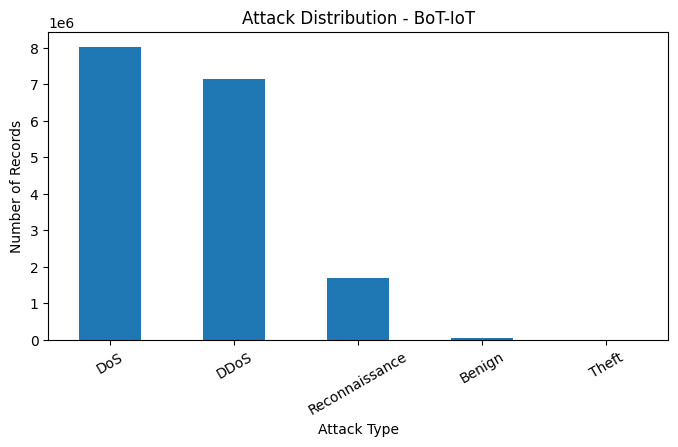

In [ ]:
import matplotlib.pyplot as plt

attack_counts.sort_values(ascending=False).plot(
    kind='bar', figsize=(8, 4)
)

plt.title('Attack Distribution - BoT-IoT')
plt.xlabel('Attack Type')
plt.ylabel('Number of Records')
plt.xticks(rotation=30)
plt.show()

In [ ]:
label_counts = pd.Series(dtype='int64')

for chunk in pd.read_csv(
    path, usecols=['Label'], chunksize=100000
):
    label_counts = label_counts.add(
        chunk['Label'].value_counts(), fill_value=0
    )

label_counts = label_counts.astype(int)

print(label_counts)
print("\nPercentages:")
print((label_counts / label_counts.sum() * 100).round(2))

Label
0       51989
1    16881819
dtype: int64

Percentages:
Label
0     0.31
1    99.69
dtype: float64


In [ ]:
print(df.dtypes.to_string())

FLOW_START_MILLISECONDS          int64
FLOW_END_MILLISECONDS            int64
IPV4_SRC_ADDR                   object
L4_SRC_PORT                      int64
IPV4_DST_ADDR                   object
L4_DST_PORT                      int64
PROTOCOL                         int64
L7_PROTO                       float64
IN_BYTES                         int64
IN_PKTS                          int64
OUT_BYTES                        int64
OUT_PKTS                         int64
TCP_FLAGS                        int64
CLIENT_TCP_FLAGS                 int64
SERVER_TCP_FLAGS                 int64
FLOW_DURATION_MILLISECONDS       int64
DURATION_IN                      int64
DURATION_OUT                     int64
MIN_TTL                          int64
MAX_TTL                          int64
LONGEST_FLOW_PKT                 int64
SHORTEST_FLOW_PKT                int64
MIN_IP_PKT_LEN                   int64
MAX_IP_PKT_LEN                   int64
SRC_TO_DST_SECOND_BYTES        float64
DST_TO_SRC_SECOND_BYTES  

In [ ]:
sample = pd.read_csv(path, nrows=100000)

sample.describe().T

,count,mean,std,min,25%,50%,75%,max
FLOW_START_MILLISECONDS,100000.0,1.528098e+12,2.954379e+06,1.528096e+12,1.528096e+12,1.528097e+12,1.528098e+12,1.528106e+12
FLOW_END_MILLISECONDS,100000.0,1.528098e+12,2.955482e+06,1.528096e+12,1.528096e+12,1.528097e+12,1.528098e+12,1.528106e+12
L4_SRC_PORT,100000.0,3.929738e+04,1.942561e+04,0.000000e+00,1.955800e+04,4.587650e+04,5.600400e+04,6.553500e+04
L4_DST_PORT,100000.0,3.586504e+02,3.572949e+03,0.000000e+00,8.000000e+01,8.000000e+01,8.000000e+01,6.099800e+04
PROTOCOL,100000.0,6.013990e+00,4.665367e-01,6.000000e+00,6.000000e+00,6.000000e+00,6.000000e+00,5.800000e+01
L7_PROTO,100000.0,7.019852e+00,1.539915e+00,0.000000e+00,7.000000e+00,7.000000e+00,7.000000e+00,1.020000e+02
IN_BYTES,100000.0,1.075351e+04,2.851595e+05,5.200000e+01,4.600000e+02,6.000000e+02,7.400000e+02,9.599176e+06
IN_PKTS,100000.0,1.732508e+01,3.206708e+02,1.000000e+00,4.000000e+00,5.000000e+00,6.000000e+00,9.678000e+03
OUT_BYTES,100000.0,4.726874e+03,2.002724e+05,0.000000e+00,0.000000e+00,0.000000e+00,4.400000e+01,9.599113e+06
OUT_PKTS,100000.0,5.782330e+00,2.080035e+02,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00,9.678000e+03


In [ ]:
features = [
    'IN_BYTES',
    'OUT_BYTES',
    'IN_PKTS',
    'OUT_PKTS',
    'FLOW_DURATION_MILLISECONDS',
    'SRC_TO_DST_AVG_THROUGHPUT'
]

sample[features].describe().T

,count,mean,std,min,25%,50%,75%,max
IN_BYTES,100000.0,10753.50622,285159.510854,52.0,460.0,600.0,740.0,9599176.0
OUT_BYTES,100000.0,4726.87358,200272.385027,0.0,0.0,0.0,44.0,9599113.0
IN_PKTS,100000.0,17.32508,320.670819,1.0,4.0,5.0,6.0,9678.0
OUT_PKTS,100000.0,5.78233,208.003493,0.0,0.0,0.0,1.0,9678.0
FLOW_DURATION_MILLISECONDS,100000.0,22318.36511,17086.534827,0.0,14742.0,18095.0,27926.0,120994.0
SRC_TO_DST_AVG_THROUGHPUT,100000.0,117925.45539,355618.171510,11.0,173.0,249.0,512.0,7072000.0


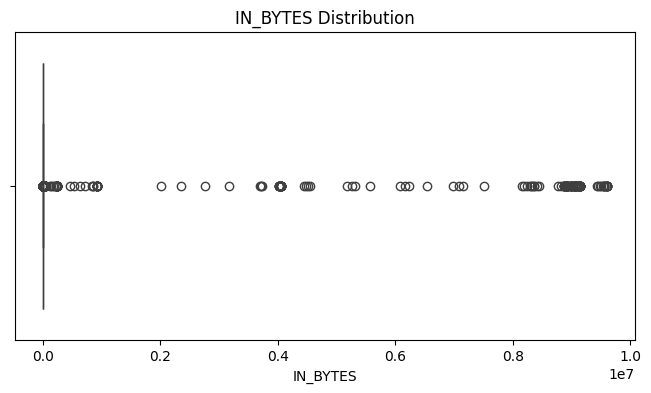

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 4))
sns.boxplot(x=sample['IN_BYTES'])
plt.title('IN_BYTES Distribution')
plt.show()

In [ ]:
Q1 = sample['IN_BYTES'].quantile(0.25)
Q3 = sample['IN_BYTES'].quantile(0.75)

IQR = Q3 - Q1
upper_bound = Q3 + 1.5 * IQR

outliers = (sample['IN_BYTES'] > upper_bound).sum()

print("Upper bound:", upper_bound)
print("Potential outliers:", outliers)
print("Percentage:", round(outliers / len(sample) * 100, 2), "%")

Upper bound: 1160.0
Potential outliers: 1129
Percentage: 1.13 %


In [ ]:
import numpy as np

numeric = sample.select_dtypes(include='number')

inf_counts = np.isinf(numeric).sum()

print(inf_counts[inf_counts > 0])

SRC_TO_DST_SECOND_BYTES      145
DST_TO_SRC_SECOND_BYTES    13075
dtype: int64


In [ ]:
inf_mask = np.isinf(sample['DST_TO_SRC_SECOND_BYTES'])

print("Infinite values:", inf_mask.sum())

print("With zero duration:",
      (sample.loc[inf_mask, 'FLOW_DURATION_MILLISECONDS'] == 0).sum())

Infinite values: 13075
With zero duration: 13075


In [ ]:
inf_mask = np.isinf(sample['SRC_TO_DST_SECOND_BYTES'])

print("Infinite values:", inf_mask.sum())

print("With zero duration:",
      (sample.loc[inf_mask, 'FLOW_DURATION_MILLISECONDS'] == 0).sum())

Infinite values: 145
With zero duration: 145


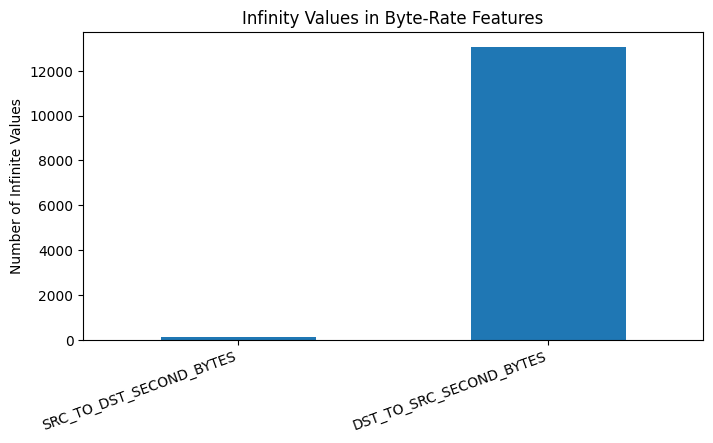

In [ ]:
inf_counts[inf_counts > 0].plot(kind='bar', figsize=(8, 4))

plt.title('Infinity Values in Byte-Rate Features')
plt.ylabel('Number of Infinite Values')
plt.xticks(rotation=20, ha='right')
plt.show()